# 03 · Vocabulary, N-grams & Word Clouds
**Part of the [Sentiment Analysis on IMDB 50K](README.md) project.** Previous: [02 Text statistics](02_eda_text_statistics.ipynb).

Now we look *inside* the words: which are most common, which words separate positive from negative, which phrases (bigrams / trigrams) carry sentiment, and how vocabulary size grows.

In [1]:
import warnings; warnings.filterwarnings('ignore')
import re, string, collections
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.feature_extraction.text import CountVectorizer, ENGLISH_STOP_WORDS
from wordcloud import WordCloud
sns.set_theme(style='whitegrid')
PAL = {'negative':'#d9534f','positive':'#5cb85c'}
df = pd.read_csv('data/imdb_dedup.csv')
df['text'] = df['review'].str.replace(r'<[^>]+>',' ',regex=True).str.lower()
df['text'] = df['text'].str.replace(r'[^a-z\s\']',' ',regex=True).str.replace(r'\s+',' ',regex=True).str.strip()
print(df.shape)

(49582, 4)


In [2]:
df[['text','sentiment']].head(3)

,text,sentiment
0,one of the other reviewers has mentioned that ...,positive
1,a wonderful little production the filming tech...,positive
2,i thought this was a wonderful way to spend ti...,positive


## 1. Tokenise and count every word

In [3]:
tokens = df['text'].str.split()
all_words = [w for t in tokens for w in t]
print('Total tokens:', f'{len(all_words):,}'); print('Vocabulary (unique):', f'{len(set(all_words)):,}')

Total tokens: 11,401,952
Vocabulary (unique): 119,364


In [4]:
freq = collections.Counter(all_words)
freq.most_common(25)

[('the', 661752),
 ('and', 322077),
 ('a', 320675),
 ('of', 287318),
 ('to', 266085),
 ('is', 209613),
 ('in', 185349),
 ('it', 155745),
 ('i', 153680),
 ('this', 149761),
 ('that', 136022),
 ('was', 94796),
 ('as', 91080),
 ('for', 86809),
 ('with', 86711),
 ('movie', 86376),
 ('but', 82914),
 ('film', 77153),
 ('on', 67496),
 ('not', 60243),
 ('you', 59798),
 ('are', 57949),
 ('his', 57226),
 ('have', 54731),
 ('be', 52915)]

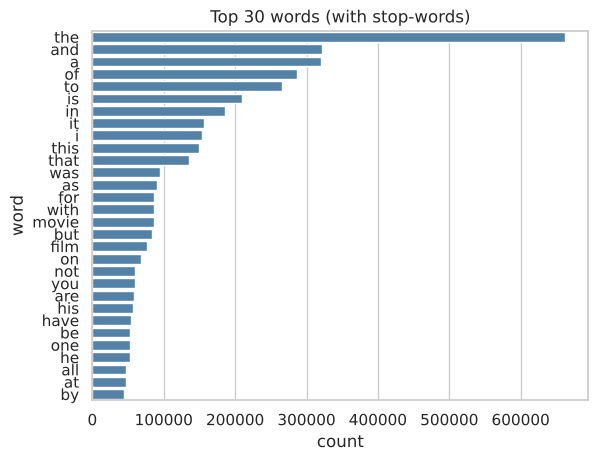

In [5]:
top = pd.DataFrame(freq.most_common(30), columns=['word','count'])
sns.barplot(data=top, y='word', x='count', color='steelblue'); plt.title('Top 30 words (with stop-words)'); plt.show()

As always in English the top words are function words (*the, and, a, of …*) — useless for sentiment. We remove them next.

## 2. Stop-words

In [6]:
stop = set(ENGLISH_STOP_WORDS) - {'not','no','nor','never','nothing','cannot'}
print(len(stop), 'stop-words, e.g.', sorted(stop)[:15])

312 stop-words, e.g. ['a', 'about', 'above', 'across', 'after', 'afterwards', 'again', 'against', 'all', 'almost', 'alone', 'along', 'already', 'also', 'although']


We deliberately **keep negations** (*not, no, never*) — removing them would turn *“not good”* into *“good”*. We'll test this claim in notebook 05.

In [7]:
stop_share = sum(c for w,c in freq.items() if w in stop)/len(all_words)
print(f'Stop-words make up {stop_share*100:.1f}% of all tokens')

Stop-words make up 51.8% of all tokens


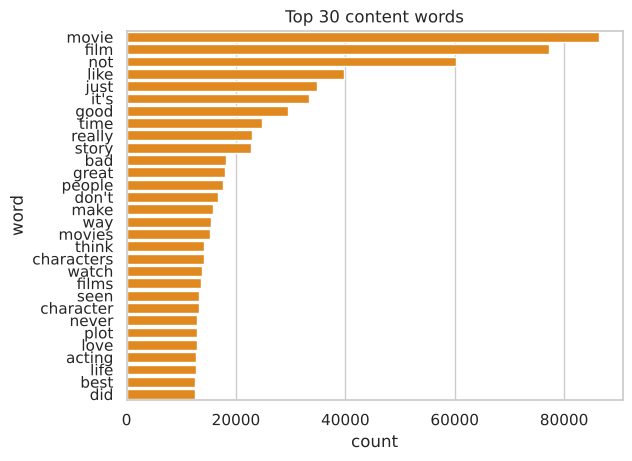

In [8]:
content = [w for w in all_words if w not in stop and len(w)>2]
freq_c = collections.Counter(content)
top = pd.DataFrame(freq_c.most_common(30), columns=['word','count'])
sns.barplot(data=top, y='word', x='count', color='darkorange'); plt.title('Top 30 content words'); plt.show()

In [9]:
top.head(15)

,word,count
0,movie,86376
1,film,77153
2,not,60243
3,like,39832
4,just,34909
5,it's,33268
6,good,29449
7,time,24837
8,really,22917
9,story,22817


*movie* and *film* dominate — domain words that appear in both classes. The interesting question is which words are **more common in one class**.

## 3. Word frequency by class

In [10]:
def class_counter(label):
    c = collections.Counter()
    for t in df.loc[df.sentiment==label,'text'].str.split():
        c.update(w for w in t if w not in stop and len(w)>2)
    return c
cpos, cneg = class_counter('positive'), class_counter('negative')
print(len(cpos), len(cneg))

86464 82121


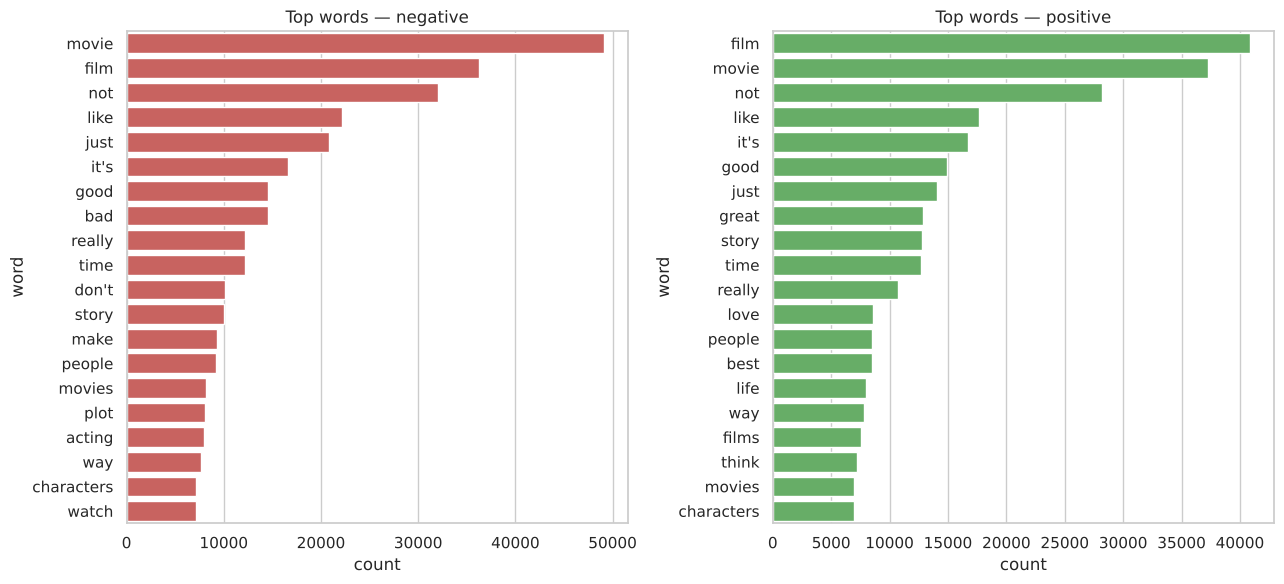

In [11]:
fig, ax = plt.subplots(1,2, figsize=(13,6))
for a,(c,col,t) in zip(ax,[(cneg,PAL['negative'],'negative'),(cpos,PAL['positive'],'positive')]):
    d=pd.DataFrame(c.most_common(20),columns=['word','count']); sns.barplot(data=d,y='word',x='count',color=col,ax=a); a.set_title(f'Top words — {t}')
plt.tight_layout(); plt.show()

## 4. Word clouds

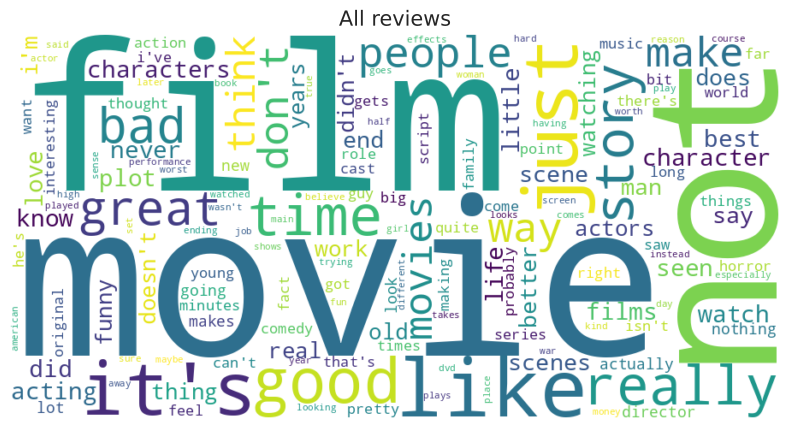

In [12]:
def cloud(counter, title, cmap):
    wc = WordCloud(width=900, height=450, background_color='white', colormap=cmap, max_words=150).generate_from_frequencies(counter)
    plt.figure(figsize=(10,5)); plt.imshow(wc, interpolation='bilinear'); plt.axis('off'); plt.title(title, fontsize=15); plt.show()
cloud(freq_c, 'All reviews', 'viridis')

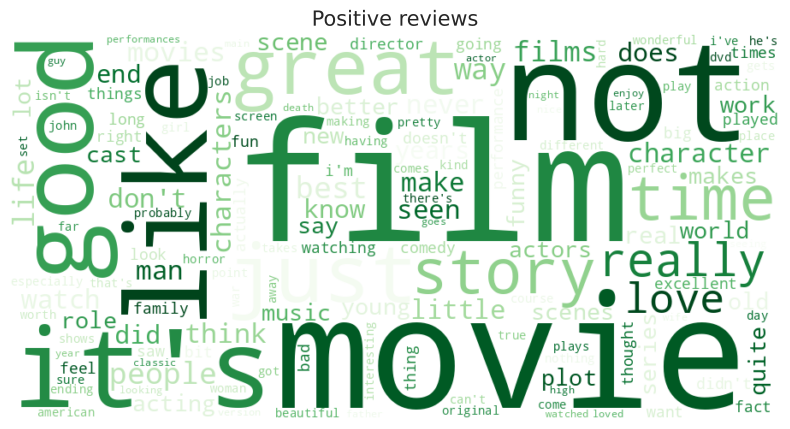

In [13]:
cloud(cpos, 'Positive reviews', 'Greens')

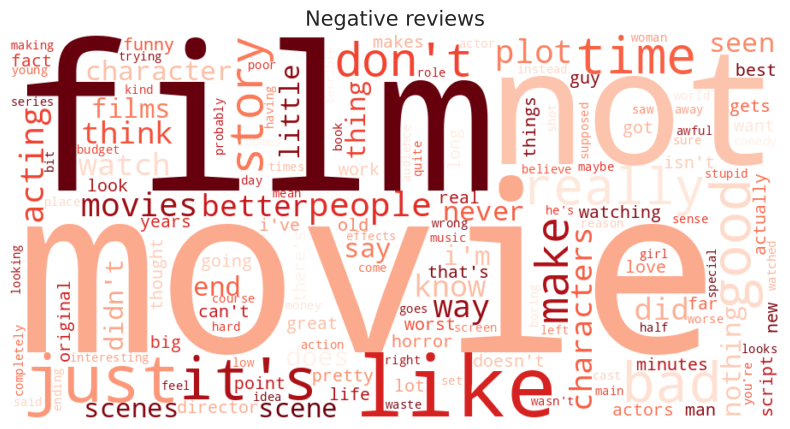

In [14]:
cloud(cneg, 'Negative reviews', 'Reds')

## 5. Discriminative words — log-odds ratio

In [15]:
vocab = [w for w in freq_c if freq_c[w]>=100]
N_pos, N_neg = sum(cpos.values()), sum(cneg.values())
rows=[]
for w in vocab:
    p=(cpos[w]+1)/(N_pos+len(vocab)); q=(cneg[w]+1)/(N_neg+len(vocab))
    rows.append((w, cpos[w], cneg[w], np.log(p/q)))
lo = pd.DataFrame(rows, columns=['word','pos_count','neg_count','log_odds']).sort_values('log_odds')
print(len(lo),'words with ≥100 occurrences')

6520 words with ≥100 occurrences


In [16]:
lo.head(15)

,word,pos_count,neg_count,log_odds
5650,uwe,1,151,-4.362672
523,boll,2,183,-4.148262
2678,stinker,10,207,-2.971582
894,mst,18,344,-2.931044
2433,turd,6,106,-2.758858
391,waste,175,2580,-2.717387
5361,yawn,9,135,-2.642009
4150,seagal,26,364,-2.635999
2343,unwatchable,15,205,-2.587226
2797,incoherent,18,223,-2.499146


In [17]:
lo.tail(15).iloc[::-1]

,word,pos_count,neg_count,log_odds
5752,ponyo,133,0,4.865901
4144,custer,156,7,2.944865
3419,edie,112,5,2.903690
5749,miyazaki,113,6,2.758349
6465,felix,159,9,2.740650
3236,matthau,229,14,2.698090
2285,prot,120,9,2.461267
6091,paulie,105,8,2.434276
4544,devito,101,8,2.395809
3054,haines,96,8,2.345548


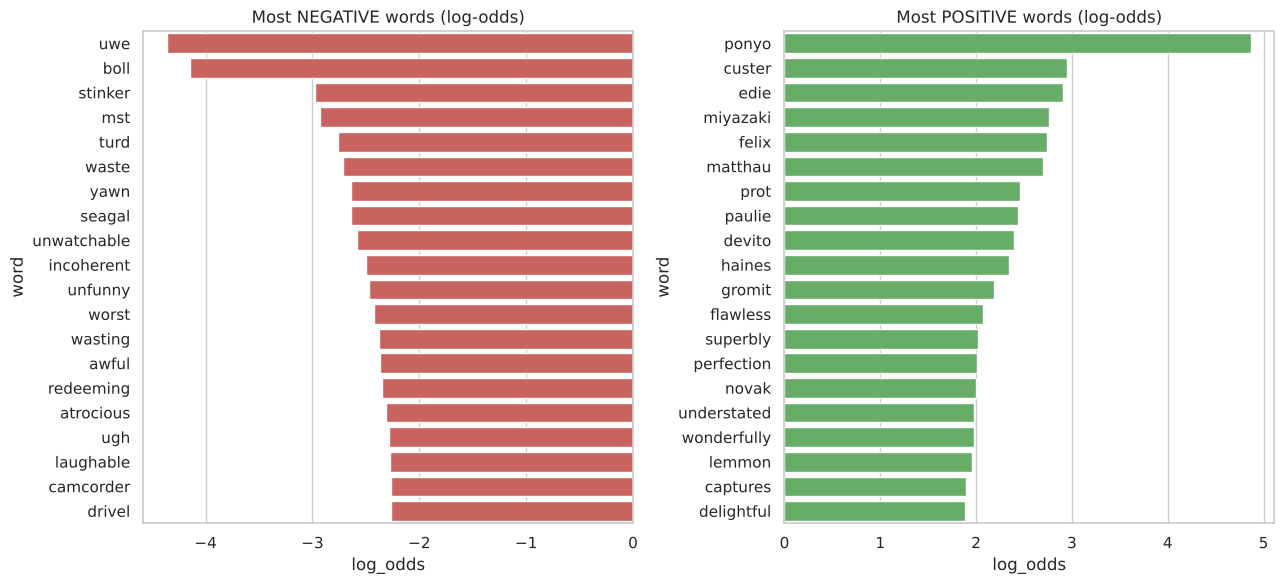

In [18]:
fig, ax = plt.subplots(1,2, figsize=(13,6))
sns.barplot(data=lo.head(20), y='word', x='log_odds', color=PAL['negative'], ax=ax[0]); ax[0].set_title('Most NEGATIVE words (log-odds)')
sns.barplot(data=lo.tail(20).iloc[::-1], y='word', x='log_odds', color=PAL['positive'], ax=ax[1]); ax[1].set_title('Most POSITIVE words (log-odds)')
plt.tight_layout(); plt.show()

Notice words like *waste, worst, awful* (negative) versus *superb, wonderful, favorite* (positive) — a linear model on word counts will find exactly these.

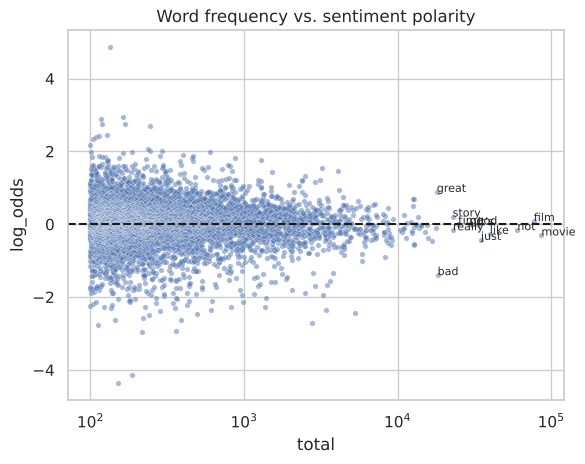

In [19]:
lo['total']=lo.pos_count+lo.neg_count
sns.scatterplot(data=lo, x='total', y='log_odds', alpha=.5, s=15); plt.xscale('log'); plt.axhline(0,color='k',ls='--'); plt.title('Word frequency vs. sentiment polarity')
for _,r in lo.sort_values('total',ascending=False).head(12).iterrows(): plt.annotate(r.word,(r.total,r.log_odds),fontsize=8)
plt.show()

## 6. Zipf's law

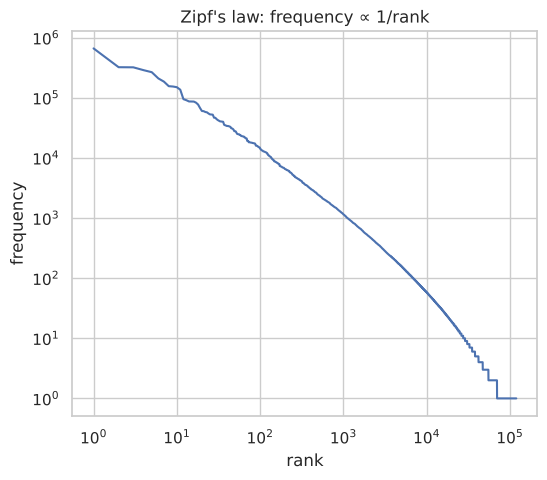

In [20]:
ranks = np.arange(1, len(freq)+1); counts_sorted = np.array(sorted(freq.values(), reverse=True))
plt.figure(figsize=(6,5)); plt.loglog(ranks, counts_sorted); plt.xlabel('rank'); plt.ylabel('frequency'); plt.title("Zipf's law: frequency ∝ 1/rank"); plt.show()

In [21]:
slope = np.polyfit(np.log(ranks[:5000]), np.log(counts_sorted[:5000]), 1)[0]; print('Fitted log-log slope (Zipf≈-1):', round(slope,3))

Fitted log-log slope (Zipf≈-1): -1.143


In [22]:
cum = np.cumsum(counts_sorted)/counts_sorted.sum()
for k in [100,1000,5000,10000,20000]:
    print(f'Top {k:>6,} words cover {cum[k-1]*100:.1f}% of all tokens')

Top    100 words cover 50.6% of all tokens
Top  1,000 words cover 76.3% of all tokens
Top  5,000 words cover 90.1% of all tokens
Top 10,000 words cover 94.2% of all tokens
Top 20,000 words cover 97.1% of all tokens


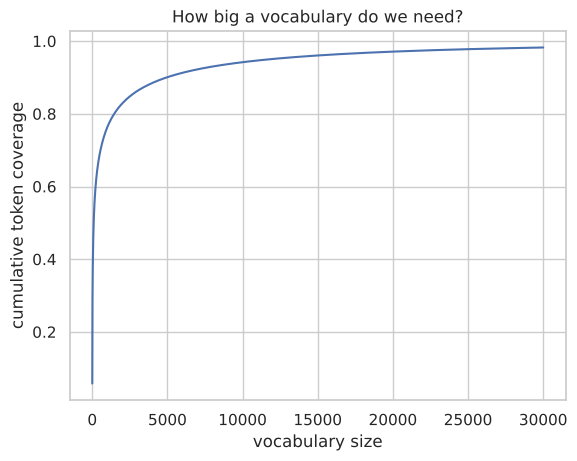

In [23]:
plt.plot(cum[:30000]); plt.xlabel('vocabulary size'); plt.ylabel('cumulative token coverage'); plt.title('How big a vocabulary do we need?'); plt.grid(True); plt.show()

In [24]:
hapax = sum(1 for c in freq.values() if c==1); print(f'Words that appear exactly once: {hapax:,} ({hapax/len(freq)*100:.1f}% of vocabulary)')

Words that appear exactly once: 49,409 (41.4% of vocabulary)


About 41% of the vocabulary appears only once (typos, names). A cap of 20–30k words keeps >97% of the text — a good setting for TF-IDF and embeddings.

## 7. Vocabulary growth (Heaps' law)

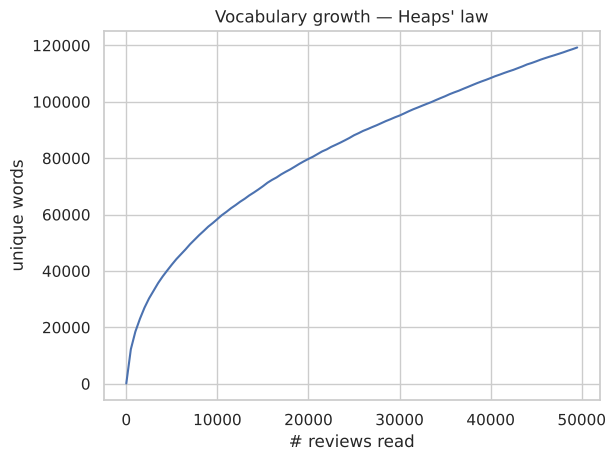

In [25]:
seen=set(); growth=[]
for i,t in enumerate(tokens.sample(frac=1, random_state=0)):
    seen.update(t)
    if i%500==0: growth.append((i, len(seen)))
g=pd.DataFrame(growth, columns=['reviews','vocab'])
plt.plot(g.reviews, g.vocab); plt.xlabel('# reviews read'); plt.ylabel('unique words'); plt.title("Vocabulary growth — Heaps' law"); plt.show()

The curve never fully flattens: new reviews keep bringing new rare words → models must handle out-of-vocabulary tokens.

## 8. N-grams

Single words miss context (*“not good”*). Bigrams and trigrams capture it.

In [26]:
def top_ngrams(texts, n, k=20, min_df=5):
    cv = CountVectorizer(ngram_range=(n,n), stop_words=None, min_df=min_df, max_features=50000)
    X = cv.fit_transform(texts); s = np.asarray(X.sum(axis=0)).ravel()
    idx = s.argsort()[::-1][:k]; return [(cv.get_feature_names_out()[i], int(s[i])) for i in idx]
top_ngrams(df['text'], 2)

[('of the', 76826),
 ('in the', 50122),
 ('this movie', 31313),
 ('the film', 26774),
 ('and the', 26522),
 ('the movie', 23793),
 ('to the', 23574),
 ('to be', 23310),
 ('this film', 21694),
 ('it is', 19785),
 ('this is', 18515),
 ('on the', 17884),
 ('it was', 17001),
 ('one of', 16154),
 ('for the', 15835),
 ('with the', 15664),
 ('if you', 13937),
 ('is the', 13666),
 ('at the', 13553),
 ('in this', 12249)]

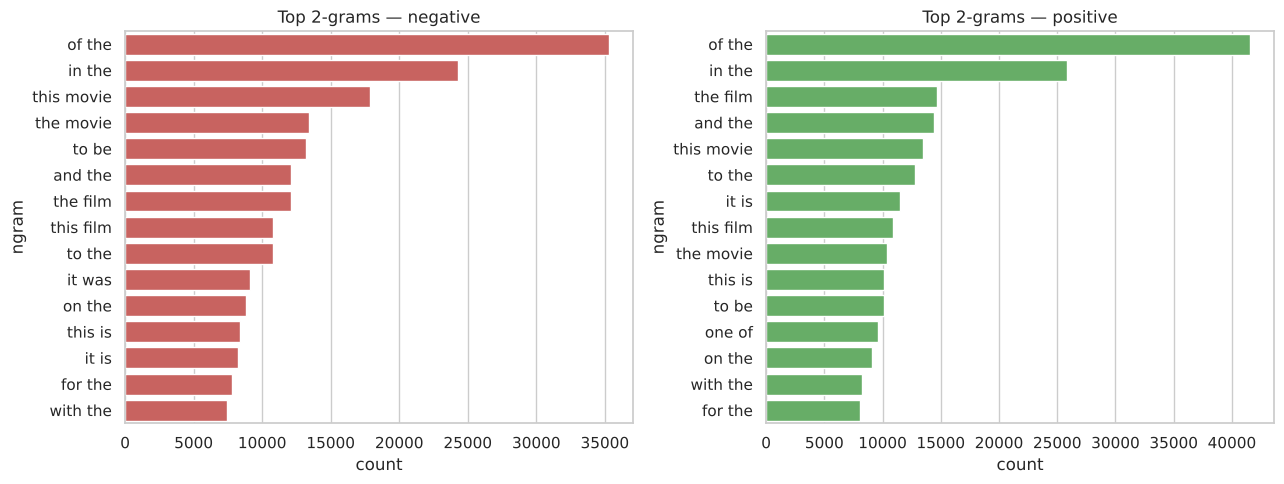

In [27]:
def plot_ngrams(n, k=15):
    fig, ax = plt.subplots(1,2, figsize=(13,5))
    for a,(lab) in zip(ax,['negative','positive']):
        d = pd.DataFrame(top_ngrams(df.loc[df.sentiment==lab,'text'], n, k), columns=['ngram','count'])
        sns.barplot(data=d,y='ngram',x='count',color=PAL[lab],ax=a); a.set_title(f'Top {n}-grams — {lab}')
    plt.tight_layout(); plt.show()
plot_ngrams(2)

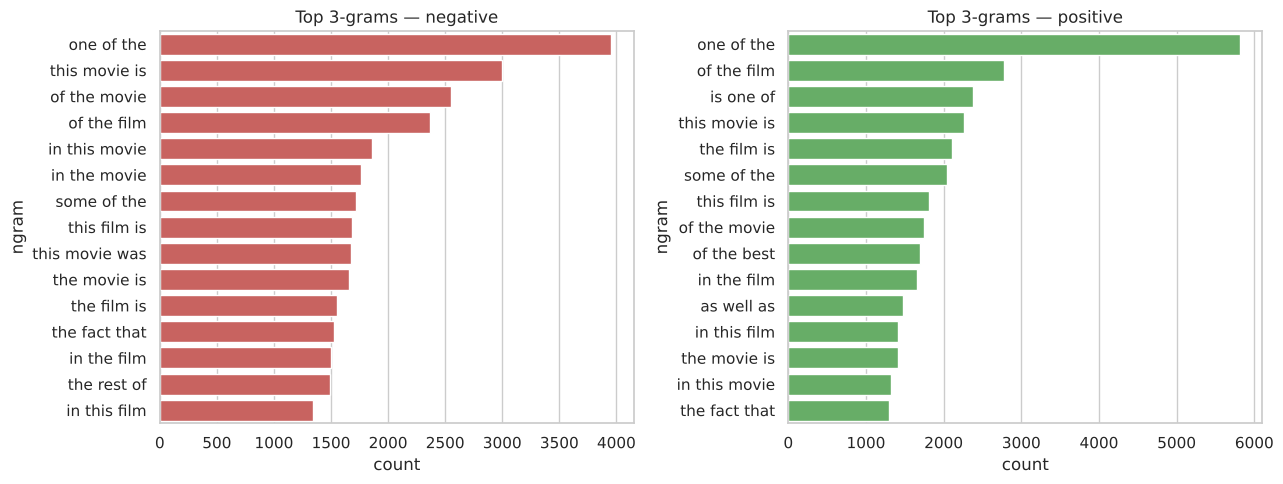

In [28]:
plot_ngrams(3)

### 8.1 Bigrams that survive stop-word filtering

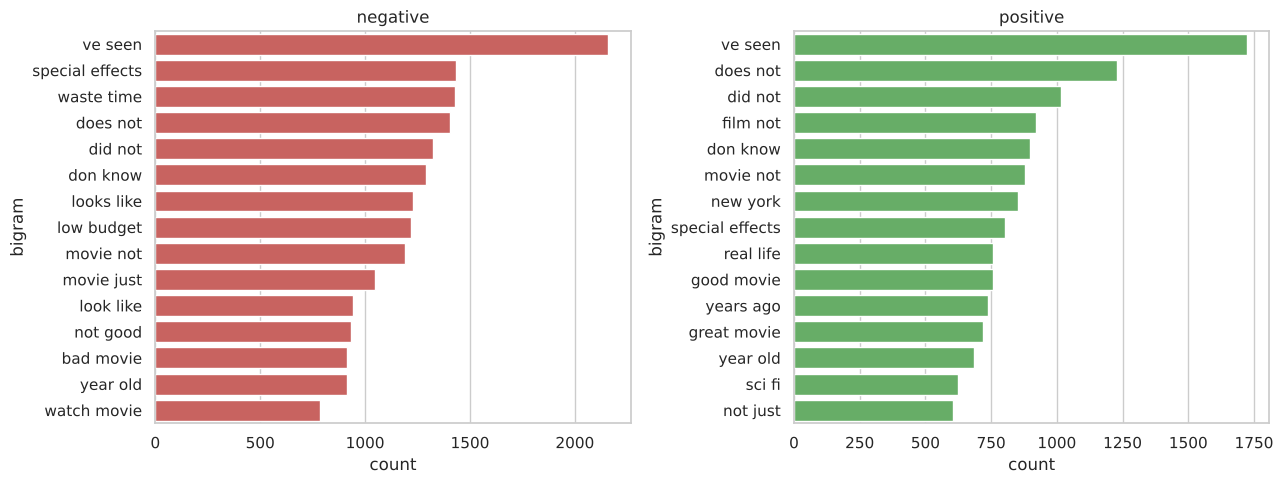

In [29]:
def clean_bigrams(texts, k=15):
    cv = CountVectorizer(ngram_range=(2,2), stop_words=list(stop), min_df=5, max_features=50000)
    X=cv.fit_transform(texts); s=np.asarray(X.sum(axis=0)).ravel(); idx=s.argsort()[::-1][:k]
    return pd.DataFrame([(cv.get_feature_names_out()[i], int(s[i])) for i in idx], columns=['bigram','count'])
fig, ax = plt.subplots(1,2, figsize=(13,5))
for a,lab in zip(ax,['negative','positive']):
    sns.barplot(data=clean_bigrams(df.loc[df.sentiment==lab,'text']),y='bigram',x='count',color=PAL[lab],ax=a); a.set_title(lab)
plt.tight_layout(); plt.show()

### 8.2 Which bigrams are most polarised?

In [30]:
cv2 = CountVectorizer(ngram_range=(2,2), min_df=30, binary=True); X2 = cv2.fit_transform(df['text'])
y = df['label'].values
pos = np.asarray(X2[y==1].sum(axis=0)).ravel()+1; neg = np.asarray(X2[y==0].sum(axis=0)).ravel()+1
bg = pd.DataFrame({'bigram':cv2.get_feature_names_out(),'pos':pos-1,'neg':neg-1,'log_odds':np.log((pos/pos.sum())/(neg/neg.sum()))}).sort_values('log_odds')
print(X2.shape[1],'bigrams with ≥30 docs')
bg.head(12)

37981 bigrams with ≥30 docs


,bigram,pos,neg,log_odds
32487,this turkey,0,134,-4.890753
32286,this garbage,1,165,-4.404319
32452,this stinker,0,79,-4.367505
28532,terrible movie,1,149,-4.302966
32421,this rubbish,0,71,-4.262144
35432,wasted my,0,65,-4.175133
32500,this waste,0,65,-4.175133
32322,this junk,0,63,-4.144361
22522,only redeeming,1,124,-4.120645
13960,horrible it,0,61,-4.112613


In [31]:
bg.tail(12).iloc[::-1]

,bigram,pos,neg,log_odds
15752,is timeless,50,0,3.946347
15348,is flawless,46,0,3.864669
24385,raoul walsh,38,0,3.678083
15382,is gripping,32,0,3.511029
8689,eight title,30,0,3.448509
34704,very touching,82,2,3.334750
26712,simply amazing,47,1,3.192576
3027,are amazing,65,2,3.105564
15195,is breathtaking,43,1,3.105564
4822,best roles,42,1,3.082575


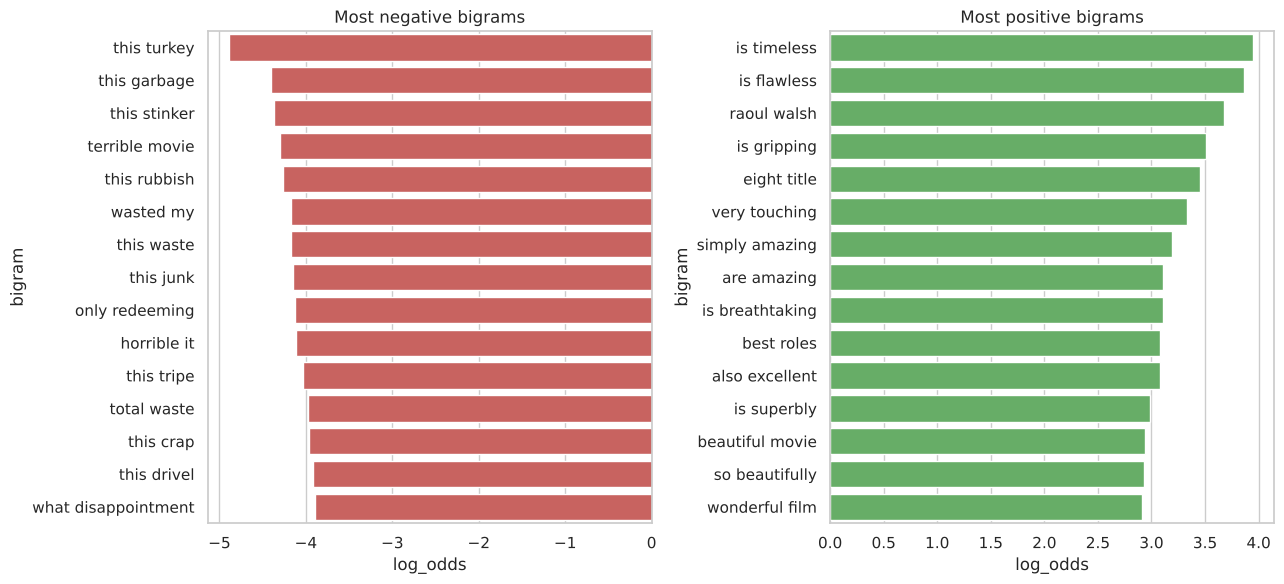

In [32]:
fig, ax = plt.subplots(1,2, figsize=(13,6))
sns.barplot(data=bg.head(15),y='bigram',x='log_odds',color=PAL['negative'],ax=ax[0]); sns.barplot(data=bg.tail(15).iloc[::-1],y='bigram',x='log_odds',color=PAL['positive'],ax=ax[1])
ax[0].set_title('Most negative bigrams'); ax[1].set_title('Most positive bigrams'); plt.tight_layout(); plt.show()

## 9. Negation matters

In [33]:
neg_pat = re.compile(r"\b(not|no|never|n't|nothing|hardly)\s+(\w+)")
ex = df['review'].str.lower().str.extractall(r"\b(not|never)\s+(good|bad|great|worth|funny)\b")
ex.value_counts().head(10)

0      1    
not    funny    466
       worth    450
       bad      291
       good     261
       great    149
never  funny     12
       good       6
       worth      1
       bad        1
       great      1
Name: count, dtype: int64

In [34]:
for w in ['good','great','bad']:
    plain = df['text'].str.contains(rf'\b{w}\b'); neg_ = df['text'].str.contains(rf'\bnot {w}\b')
    print(f"{w:6s} P(pos | 'not {w}') = {df.loc[neg_,'label'].mean():.3f}  vs P(pos | '{w}') = {df.loc[plain,'label'].mean():.3f}   (n={neg_.sum()})")

good   P(pos | 'not good') = 0.198  vs P(pos | 'good') = 0.495   (n=257)


great  P(pos | 'not great') = 0.533  vs P(pos | 'great') = 0.675   (n=150)


bad    P(pos | 'not bad') = 0.355  vs P(pos | 'bad') = 0.253   (n=282)


*“not good”* flips the polarity of *“good”* completely — the key reason we use n-grams and keep negations.

## 10. Rare, strange and repeated tokens

In [35]:
rare = [w for w,c in freq.items() if c==1]; import random; random.seed(1); random.sample(rare, 20)

["landscape'",
 'holidaying',
 "zip's",
 'hansons',
 'nees',
 'bourbage',
 "'bought",
 'afterstory',
 "baba's",
 'sexworker',
 'outstripping',
 'polemicist',
 "verghese's",
 "prejudice'",
 'toxicology',
 "olan's",
 "'adulthood'",
 'revenant',
 'snoozes',
 'redistribute']

In [36]:
elong = df['text'].str.extractall(r'\b(\w*(\w)\2{2,}\w*)\b')[0].value_counts().head(10); elong

0
iii       241
www       143
hmmm       95
soooo      48
sooo       45
sooooo     33
xxx        32
hmmmm      31
ummm       21
oooh       20
Name: count, dtype: int64

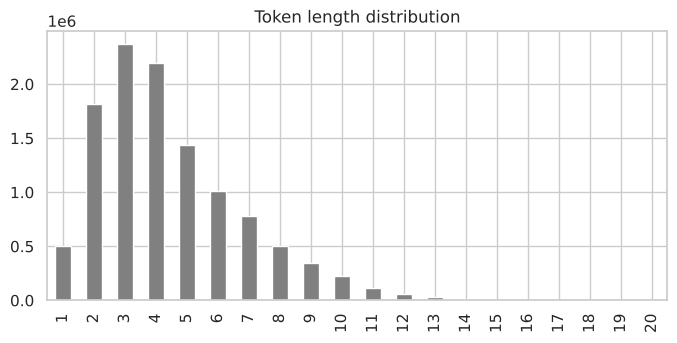

In [37]:
pd.Series(collections.Counter(len(w) for w in all_words)).sort_index().loc[:20].plot(kind='bar', figsize=(8,3.5), color='gray'); plt.title('Token length distribution'); plt.show()

## 11. Characters, movie words and topics (quick look)

In [38]:
themes = {'acting':r'act(?:or|ors|ing|ress)','plot':r'\bplot\b|story','music':r'music|soundtrack|score','direction':r'direct(?:or|ion|ed)','effects':r'effects|cgi','ending':r'\bending\b|\bend\b'}
rows=[]
for k,p in themes.items():
    m = df['text'].str.contains(p, regex=True); rows.append((k, m.mean()*100, df.loc[m,'label'].mean()))
th = pd.DataFrame(rows, columns=['theme','% reviews mentioning','P(positive)']).set_index('theme').round(3); th

,% reviews mentioning,P(positive)
theme,,
acting,40.002,0.440
plot,47.533,0.487
music,16.286,0.595
direction,22.506,0.475
effects,8.096,0.376
ending,23.355,0.494


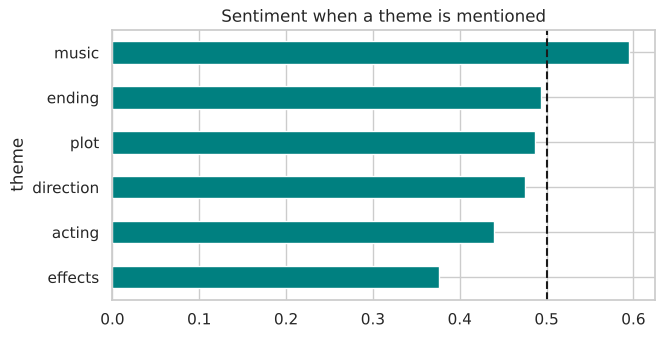

In [39]:
th['P(positive)'].sort_values().plot(kind='barh', color='teal', figsize=(7,3.5)); plt.axvline(.5,color='k',ls='--'); plt.title('Sentiment when a theme is mentioned'); plt.show()

## 12. Save a lightweight vocabulary table for later notebooks

In [40]:
vocab_df = lo[['word','pos_count','neg_count','log_odds']]; vocab_df.to_csv('data/word_polarity.csv', index=False); print(vocab_df.shape)

(6520, 4)


## 13. Summary
- ≈11.4M tokens, a ≈119k-word vocabulary; Zipf-like, with 41% of the vocabulary appearing once.
- The top 20k words cover 97% of tokens.
- Strongly polarised words (*worst, waste, awful* vs *superb, wonderful*) and bigrams (*waste of*, *must see*) drive the label.
- Negation reverses meaning → keep *not/no/never*, use n-grams.

**Next:** [04 – Text preprocessing](04_text_preprocessing.ipynb)